# 1, Calculation

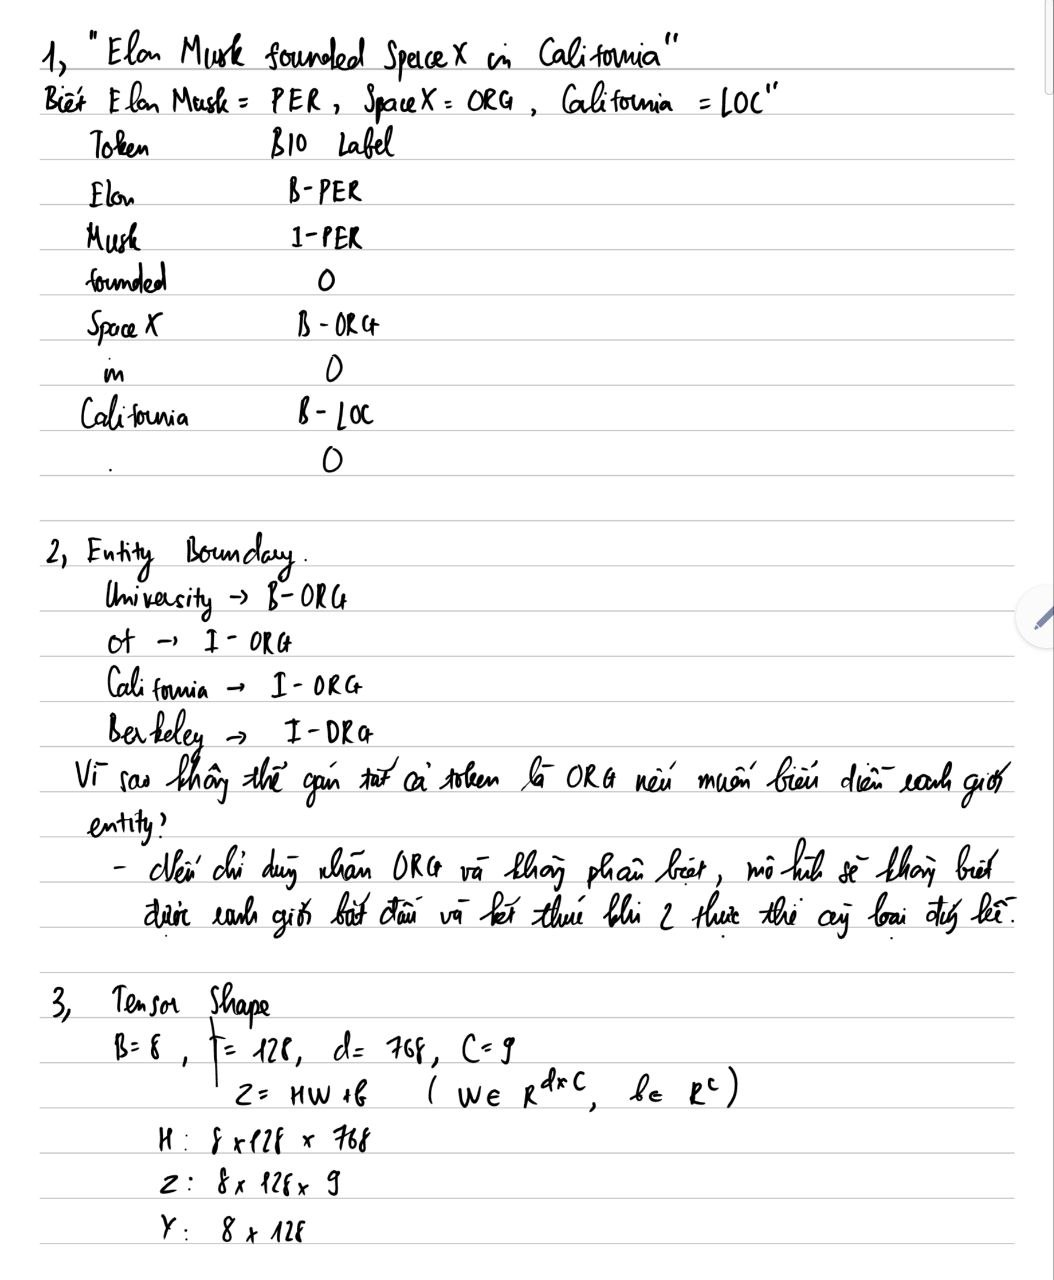

# 2, Prediction

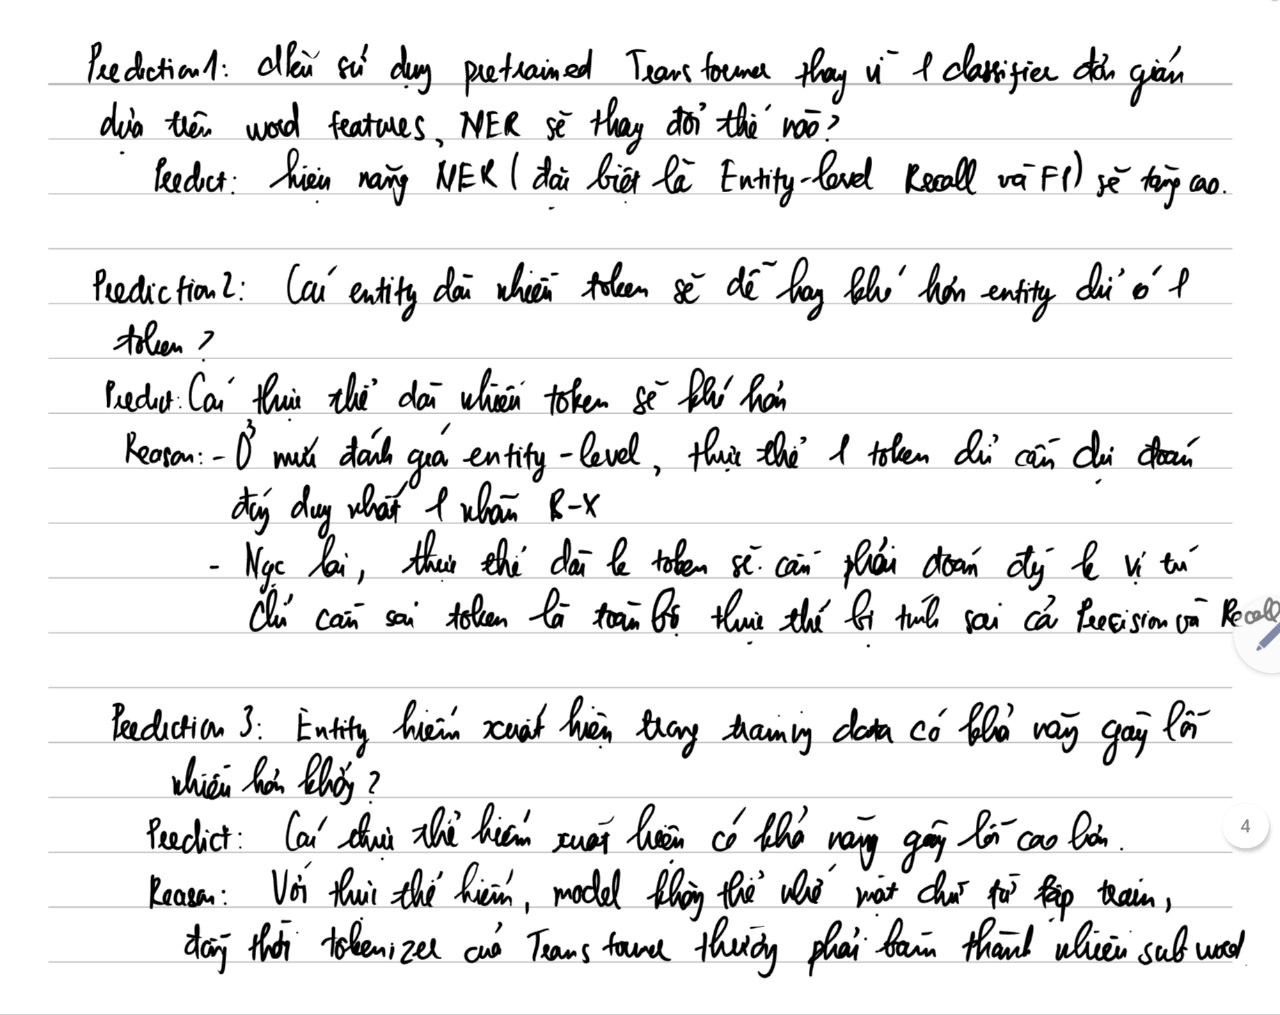

# 3, BIO & label alignment

In [1]:
%cd /content/drive/MyDrive/Classroom/K68.NLP&DL.2026.09/lab09

/content/drive/MyDrive/Classroom/K68.NLP&DL.2026.09/lab09


In [2]:
!pip install -q transformers datasets seqeval accelerate scikit-learn matplotlib seaborn pandas

In [3]:
import torch
import numpy as np
import pandas as pd

device = "cuda" if torch.cuda.is_available() else "cpu"

In [4]:
from datasets import load_dataset

raw_datasets = load_dataset("eriktks/conll2003", revision="convert/parquet")


print(raw_datasets)
print("Số câu Train:", len(raw_datasets["train"]))
print("Số câu Validation:", len(raw_datasets["validation"]))
print("Số câu Test:", len(raw_datasets["test"]))

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3453
    })
})
Số câu Train: 14041
Số câu Validation: 3250
Số câu Test: 3453


In [5]:
default_labels = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC", "B-MISC", "I-MISC"]
ner_feature = raw_datasets["train"].features["ner_tags"].feature
label_list = ner_feature.names if hasattr(ner_feature, "names") else default_labels

id2label = {i: label for i, label in enumerate(label_list)}
label2id = {label: i for i, label in enumerate(label_list)}
print("Danh sách nhãn (9 nhãn):", label_list)

sample = raw_datasets["train"][0]
print("\nMẫu câu 0:")
for w, tag_id in zip(sample["tokens"], sample["ner_tags"]):
    print(f"  {w:15s} -> {id2label[tag_id]}")

Danh sách nhãn (9 nhãn): ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']

Mẫu câu 0:
  EU              -> B-ORG
  rejects         -> O
  German          -> B-MISC
  call            -> O
  to              -> O
  boycott         -> O
  British         -> B-MISC
  lamb            -> O
  .               -> O


## Cài đặt Tokenization & Label Alignment

In [6]:
from transformers import AutoTokenizer

model_checkpoint = "bert-base-cased"
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

example_words = raw_datasets["train"][0]["tokens"]
example_tags = raw_datasets["train"][0]["ner_tags"]

enc = tokenizer(example_words, is_split_into_words=True, truncation=True)
word_ids = enc.word_ids()
tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"])

aligned_labels = []
prev_word_idx = None
for word_idx in word_ids:
    if word_idx is None:
        aligned_labels.append(-100)
    elif word_idx != prev_word_idx:
        aligned_labels.append(example_tags[word_idx])
    else:
        aligned_labels.append(-100)
    prev_word_idx = word_idx

print(f"{'Token':15s} | {'Input ID':8s} | {'Mask':4s} | {'Word ID':7s} | {'Aligned Label'}")
print("-" * 62)
for tok, iid, mask, wid, lbl in zip(tokens, enc["input_ids"], enc["attention_mask"], word_ids, aligned_labels):
    lbl_str = "IGNORE (-100)" if lbl == -100 else f"{lbl} ({id2label[lbl]})"
    print(f"{tok:15s} | {iid:8d} | {mask:4d} | {str(wid):7s} | {lbl_str}")

# Strategy A
def tokenize_and_align_labels(examples):
    tokenized_inputs = tokenizer(
        examples["tokens"],
        truncation=True,
        is_split_into_words=True
    )
    all_labels = []
    for i, label in enumerate(examples["ner_tags"]):
        word_ids = tokenized_inputs.word_ids(batch_index=i)
        prev_word_idx = None
        label_ids = []
        for word_idx in word_ids:
            if word_idx is None:
                label_ids.append(-100)
            elif word_idx != prev_word_idx:
                label_ids.append(label[word_idx])
            else:
                label_ids.append(-100)
            prev_word_idx = word_idx
        all_labels.append(label_ids)
    tokenized_inputs["labels"] = all_labels
    return tokenized_inputs

tokenized_datasets = raw_datasets.map(tokenize_and_align_labels, batched=True)
print("\nĐã tokenize & align xong toàn bộ dataset:", tokenized_datasets)

Token           | Input ID | Mask | Word ID | Aligned Label
--------------------------------------------------------------
[CLS]           |      101 |    1 | None    | IGNORE (-100)
EU              |     7270 |    1 | 0       | 3 (B-ORG)
rejects         |    22961 |    1 | 1       | 0 (O)
German          |     1528 |    1 | 2       | 7 (B-MISC)
call            |     1840 |    1 | 3       | 0 (O)
to              |     1106 |    1 | 4       | 0 (O)
boycott         |    21423 |    1 | 5       | 0 (O)
British         |     1418 |    1 | 6       | 7 (B-MISC)
la              |     2495 |    1 | 7       | 0 (O)
##mb            |    12913 |    1 | 7       | IGNORE (-100)
.               |      119 |    1 | 8       | 0 (O)
[SEP]           |      102 |    1 | None    | IGNORE (-100)

Đã tokenize & align xong toàn bộ dataset: DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags', 'input_ids', 'token_type_ids', 'attention_mask', 'labels'],
    

# 4, Tokenization Experiment

## Experiment 1: Phân tích Subword Tokenization trên tập test

In [7]:
test_data = raw_datasets["test"]

records = []
entity_words, entity_subwords, entity_splits = 0, 0, 0
non_ent_words, non_ent_subwords, non_ent_splits = 0, 0, 0
most_split_words = []

for ex in test_data:
    words = ex["tokens"]
    tags = ex["ner_tags"]
    if len(words) == 0:
        continue

    enc = tokenizer(words, is_split_into_words=True, add_special_tokens=False)
    word_ids = enc.word_ids()
    sub_tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"])

    counts = {}
    for wid in word_ids:
        counts[wid] = counts.get(wid, 0) + 1

    n_words = len(words)
    n_subwords = len(word_ids)
    n_splits = sum(1 for c in counts.values() if c > 1)
    records.append({
        "n_words": n_words,
        "n_subwords": n_subwords,
        "n_splits": n_splits,
        "R": n_subwords / n_words
    })

    for wid, (w, tag_id) in enumerate(zip(words, tags)):
        c = counts.get(wid, 1)
        if c >= 4:
            most_split_words.append((w, id2label[tag_id], c, tokenizer.tokenize(w)))
        if tag_id != 0: # Entity
            entity_words += 1
            entity_subwords += c
            if c > 1: entity_splits += 1
        else:           # Non-entity (O)
            non_ent_words += 1
            non_ent_subwords += c
            if c > 1: non_ent_splits += 1

df_tok = pd.DataFrame(records)
median_len = df_tok["n_words"].median()
short_df = df_tok[df_tok["n_words"] <= median_len]
long_df = df_tok[df_tok["n_words"] > median_len]

print("THỐNG KÊ TỔNG QUAN (TẬP TEST)")
print(f"Tổng số câu           : {len(df_tok)}")
print(f"Tổng số words         : {df_tok['n_words'].sum()}")
print(f"Tổng số subword tokens: {df_tok['n_subwords'].sum()}")
print(f"Tổng số từ bị tách    : {df_tok['n_splits'].sum()}")
print(f"Tỉ lệ R tổng thể      : {df_tok['n_subwords'].sum() / df_tok['n_words'].sum():.4f}")

print("\nSO SÁNH CÂU NGẮN VS CÂU DÀI")
print(f"Câu ngắn (<= {int(median_len)} từ): R = {short_df['n_subwords'].sum() / short_df['n_words'].sum():.4f}")
print(f"Câu dài  (>  {int(median_len)} từ): R = {long_df['n_subwords'].sum() / long_df['n_words'].sum():.4f}")

print("\nSO SÁNH ENTITY VS NON-ENTITY")
print(f"Entity words    : R = {entity_subwords / entity_words:.4f} | Tỉ lệ từ bị tách = {entity_splits / entity_words:.2%}")
print(f"Non-entity words: R = {non_ent_subwords / non_ent_words:.4f} | Tỉ lệ từ bị tách = {non_ent_splits / non_ent_words:.2%}")

print("\nVÍ DỤ CÁC TỪ BỊ CHIA THÀNH NHIỀU SUBWORD NHẤT")
seen = set()
shown = 0
for w, lbl, c, subs in sorted(most_split_words, key=lambda x: -x[2]):
    if w not in seen:
        seen.add(w)
        print(f"  {w:25s} ({lbl:6s}) -> {c} subwords: {subs}")
        shown += 1
        if shown >= 15:
            break

THỐNG KÊ TỔNG QUAN (TẬP TEST)
Tổng số câu           : 3453
Tổng số words         : 46435
Tổng số subword tokens: 63461
Tổng số từ bị tách    : 8287
Tỉ lệ R tổng thể      : 1.3667

SO SÁNH CÂU NGẮN VS CÂU DÀI
Câu ngắn (<= 9 từ): R = 1.8263
Câu dài  (>  9 từ): R = 1.2256

SO SÁNH ENTITY VS NON-ENTITY
Entity words    : R = 1.9152 | Tỉ lệ từ bị tách = 45.28%
Non-entity words: R = 1.2506 | Tỉ lệ từ bị tách = 12.04%

VÍ DỤ CÁC TỪ BỊ CHIA THÀNH NHIỀU SUBWORD NHẤT
  http://www.pt.lu/infoweb/kreschtmaart (O     ) -> 21 subwords: ['http', ':', '/', '/', 'www', '.', 'p', '##t', '.', 'l', '##u', '/', 'info', '##we', '##b', '/', 'k', '##res', '##cht', '##ma', '##art']
  FOOTBALL-THURSDAY         (O     ) -> 12 subwords: ['F', '##O', '##OT', '##BA', '##LL', '-', 'T', '##H', '##UR', '##SD', '##A', '##Y']
  FOOTBALL-STANDINGS        (O     ) -> 11 subwords: ['F', '##O', '##OT', '##BA', '##LL', '-', 'ST', '##AN', '##DI', '##NG', '##S']
  INTERVIEW-ZYWIEC          (B-MISC) -> 11 subwords: ['IN', '##TE',

Những loại từ nào thường bị chia thành nhiều subword?

- Tên riêng hiếm / tên nước ngoài
- Từ viết hoa toàn bộ hoặc chữ viết tắt
- Từ ghép có dấu gạch nối hoặc số liệu/ký hiệu
- Từ có hình thái phức tạp (tiền tố, hậu tố hiếm) hoặc từ chuyên ngành

# 5, Baseline Implementation

## Baseline (Token Features + Logistic Regression)

In [8]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from seqeval.metrics import precision_score, recall_score, f1_score, classification_report

def word2features(tokens, i):
    w = tokens[i]
    feats = {
        "word.lower": w.lower(),
        "word.isupper": w.isupper(),
        "word.istitle": w.istitle(),
        "word.isdigit": w.isdigit(),
        "prefix2": w[:2].lower(),
        "suffix2": w[-2:].lower(),
        "suffix3": w[-3:].lower(),
        "has_hyphen": "-" in w,
    }
    if i > 0:
        w_prev = tokens[i - 1]
        feats["prev.lower"] = w_prev.lower()
        feats["prev.istitle"] = w_prev.istitle()
        feats["prev.isupper"] = w_prev.isupper()
    else:
        feats["BOS"] = True

    if i < len(tokens) - 1:
        w_next = tokens[i + 1]
        feats["next.lower"] = w_next.lower()
        feats["next.istitle"] = w_next.istitle()
        feats["next.isupper"] = w_next.isupper()
    else:
        feats["EOS"] = True
    return feats

def extract_dataset_features(split_data):
    X_dicts, y_flat, sent_lengths = [], [], []
    for ex in split_data:
        toks = ex["tokens"]
        tags = ex["ner_tags"]
        sent_lengths.append(len(toks))
        for i in range(len(toks)):
            X_dicts.append(word2features(toks, i))
            y_flat.append(tags[i])
    return X_dicts, y_flat, sent_lengths

print("Trích xuất đặc trưng trên tập Train & Test...")
X_train_dict, y_train_flat, _ = extract_dataset_features(raw_datasets["train"])
X_test_dict, y_test_flat, test_lengths = extract_dataset_features(raw_datasets["test"])

vec = DictVectorizer(sparse=True)
X_train_vec = vec.fit_transform(X_train_dict)
X_test_vec = vec.transform(X_test_dict)
print("Kích thước ma trận đặc trưng Train:", X_train_vec.shape)

# Logistic Regression
baseline_clf = LogisticRegression(max_iter=200, C=1.0, random_state=42)
baseline_clf.fit(X_train_vec, y_train_flat)

y_pred_base_flat = baseline_clf.predict(X_test_vec)

base_true_seqs, base_pred_seqs = [], []
idx = 0
for length in test_lengths:
    base_true_seqs.append([id2label[t] for t in y_test_flat[idx : idx + length]])
    base_pred_seqs.append([id2label[p] for p in y_pred_base_flat[idx : idx + length]])
    idx += length

base_p = precision_score(base_true_seqs, base_pred_seqs)
base_r = recall_score(base_true_seqs, base_pred_seqs)
base_f1 = f1_score(base_true_seqs, base_pred_seqs)
base_tok_acc = accuracy_score(y_test_flat, y_pred_base_flat)

print("\nKẾT QUẢ BASELINE (LOGISTIC REGRESSION) TRÊN TEST SET")
print(f"Token-level Accuracy : {base_tok_acc:.4f}")
print(f"Entity-level Precision: {base_p:.4f}")
print(f"Entity-level Recall   : {base_r:.4f}")
print(f"Entity-level F1       : {base_f1:.4f}")
print("\nChi tiết theo loại thực thể:")
print(classification_report(base_true_seqs, base_pred_seqs, digits=4))

Trích xuất đặc trưng trên tập Train & Test...
Kích thước ma trận đặc trưng Train: (203621, 67332)

KẾT QUẢ BASELINE (LOGISTIC REGRESSION) TRÊN TEST SET
Token-level Accuracy : 0.9532
Entity-level Precision: 0.6992
Entity-level Recall   : 0.7417
Entity-level F1       : 0.7198

Chi tiết theo loại thực thể:
              precision    recall  f1-score   support

         LOC     0.7925    0.8058    0.7990      1668
        MISC     0.7382    0.7550    0.7465       702
         ORG     0.5905    0.6189    0.6044      1661
         PER     0.7010    0.7959    0.7454      1617

   micro avg     0.6992    0.7417    0.7198      5648
   macro avg     0.7055    0.7439    0.7238      5648
weighted avg     0.7001    0.7417    0.7199      5648



# 6, Transformer NER Implementation

## Khởi tạo Pretrained Transformer

In [9]:
from transformers import AutoModelForTokenClassification, DataCollatorForTokenClassification

model = AutoModelForTokenClassification.from_pretrained(
    model_checkpoint,
    num_labels=len(label_list),
    id2label=id2label,
    label2id=label2id
).to(device)

data_collator = DataCollatorForTokenClassification(tokenizer=tokenizer)

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly i

## Fine-tune BERT

In [10]:
from transformers import TrainingArguments, Trainer

def compute_metrics(eval_preds):
    logits, labels = eval_preds
    predictions = np.argmax(logits, axis=-1)

    true_labels = [
        [id2label[l] for l in label_row if l != -100]
        for label_row in labels
    ]
    true_predictions = [
        [id2label[p] for (p, l) in zip(pred_row, label_row) if l != -100]
        for pred_row, label_row in zip(predictions, labels)
    ]
    return {
        "precision": precision_score(true_labels, true_predictions),
        "recall": recall_score(true_labels, true_predictions),
        "f1": f1_score(true_labels, true_predictions),
    }

training_args = TrainingArguments(
    output_dir="./bert-ner-conll2003",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    fp16=torch.cuda.is_available(),
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    logging_steps=100,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer.train()

Epoch,Training Loss,Validation Loss,Precision,Recall,F1
1,0.049427,0.040255,0.924547,0.936217,0.930345
2,0.026602,0.036754,0.940793,0.946651,0.943713
3,0.013210,0.036526,0.939823,0.948839,0.944310


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=2634, training_loss=0.053096978883446395, metrics={'train_runtime': 331.7033, 'train_samples_per_second': 126.99, 'train_steps_per_second': 7.941, 'total_flos': 1050534559887048.0, 'train_loss': 0.053096978883446395, 'epoch': 3.0})

# 7, Entity-level evaluation

## Experiment 2 & 3: So sánh Baseline vs Transformer & Token-level vs Entity-level

In [11]:
pred_output = trainer.predict(tokenized_datasets["test"])
test_logits = pred_output.predictions
test_labels = pred_output.label_ids
test_preds = np.argmax(test_logits, axis=-1)

bert_true_seqs, bert_pred_seqs = [], []
bert_true_flat, bert_pred_flat = [], []

for pred_row, label_row in zip(test_preds, test_labels):
    t_seq, p_seq = [], []
    for p, l in zip(pred_row, label_row):
        if l != -100:
            t_seq.append(id2label[l])
            p_seq.append(id2label[p])
            bert_true_flat.append(l)
            bert_pred_flat.append(p)
    bert_true_seqs.append(t_seq)
    bert_pred_seqs.append(p_seq)

bert_p = precision_score(bert_true_seqs, bert_pred_seqs)
bert_r = recall_score(bert_true_seqs, bert_pred_seqs)
bert_f1 = f1_score(bert_true_seqs, bert_pred_seqs)
bert_tok_acc = accuracy_score(bert_true_flat, bert_pred_flat)

results_df = pd.DataFrame([
    {
        "Model": "Baseline (Token Features + Logistic Regression)",
        "Token_Accuracy": round(base_tok_acc, 4),
        "Entity_Precision": round(base_p, 4),
        "Entity_Recall": round(base_r, 4),
        "Entity_F1": round(base_f1, 4),
    },
    {
        "Model": "Pretrained Transformer (bert-base-cased)",
        "Token_Accuracy": round(bert_tok_acc, 4),
        "Entity_Precision": round(bert_p, 4),
        "Entity_Recall": round(bert_r, 4),
        "Entity_F1": round(bert_f1, 4),
    }
])
results_df.to_csv("results.csv", index=False)
print("EXPERIMENT 2: BASELINE VS TRANSFORMER")
display(results_df)

demo_gold = [["B-LOC", "I-LOC"]]
demo_pred = [["B-LOC", "O"]]
print("\nEXPERIMENT 3: TOKEN-LEVEL VS ENTITY-LEVEL ('New York')")
print("Gold: B-LOC, I-LOC | Pred: B-LOC, O")
print("  Token-level Accuracy :", accuracy_score(demo_gold[0], demo_pred[0]))
print("  Entity-level F1      :", f1_score(demo_gold, demo_pred), "(Sai ranh giới => 0 điểm entity)")

EXPERIMENT 2: BASELINE VS TRANSFORMER


,Model,Token_Accuracy,Entity_Precision,Entity_Recall,Entity_F1
0,Baseline (Token Features + Logistic Regression),0.9532,0.6992,0.7417,0.7198
1,Pretrained Transformer (bert-base-cased),0.9824,0.9033,0.9196,0.9114



EXPERIMENT 3: TOKEN-LEVEL VS ENTITY-LEVEL ('New York')
Gold: B-LOC, I-LOC | Pred: B-LOC, O
  Token-level Accuracy : 0.5
  Entity-level F1      : 0.0 (Sai ranh giới => 0 điểm entity)


## Experiment 4: Entity Type Analysis + Confusion Matrix

EXPERIMENT 4: HIỆU NĂNG THEO LOẠI ENTITY


,Entity,Precision,Recall,F1,Support
0,PER,0.9674,0.9536,0.9604,1617
1,ORG,0.8769,0.9091,0.8927,1661
2,LOC,0.9295,0.9323,0.9309,1668
3,MISC,0.7714,0.8362,0.8025,702


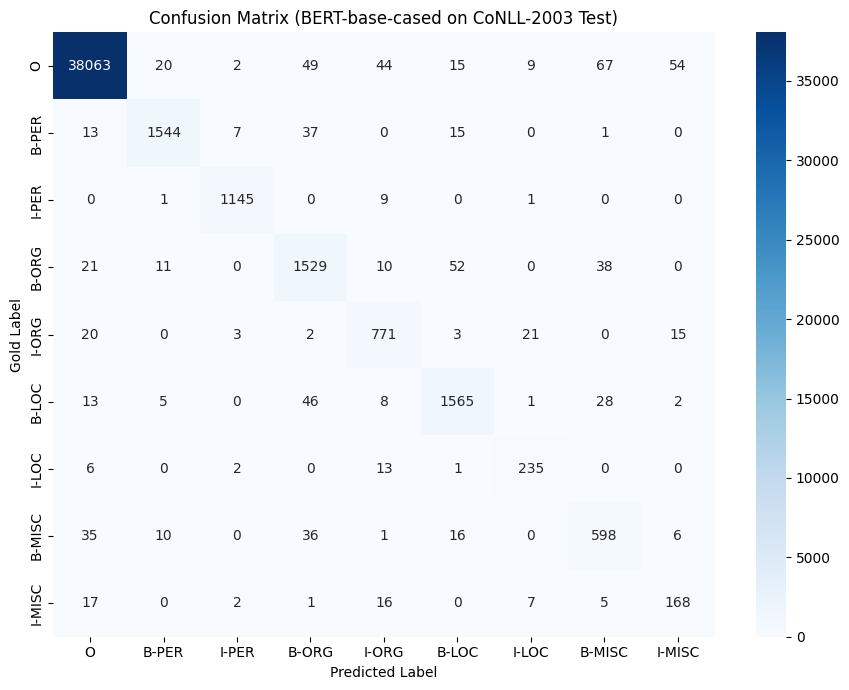

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

report_dict = classification_report(bert_true_seqs, bert_pred_seqs, output_dict=True, digits=4)
entity_rows = []
for ent in ["PER", "ORG", "LOC", "MISC"]:
    entity_rows.append({
        "Entity": ent,
        "Precision": round(report_dict[ent]["precision"], 4),
        "Recall": round(report_dict[ent]["recall"], 4),
        "F1": round(report_dict[ent]["f1-score"], 4),
        "Support": int(report_dict[ent]["support"])
    })
entity_df = pd.DataFrame(entity_rows)
entity_df.to_csv("entity_metrics.csv", index=False)

print("EXPERIMENT 4: HIỆU NĂNG THEO LOẠI ENTITY")
display(entity_df)

# Confusion Matrix
cm = confusion_matrix(bert_true_flat, bert_pred_flat, labels=list(range(len(label_list))))
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=label_list, yticklabels=label_list)
plt.title("Confusion Matrix (BERT-base-cased on CoNLL-2003 Test)")
plt.xlabel("Predicted Label")
plt.ylabel("Gold Label")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

Vì sao performance giữa các loại entity có thể khác nhau?

- PER (cao nhất): Có số lượng mẫu train lớn, lexical pattern rất rõ ràng, ranh giới ngắn gọn và ít mơ hồ.

- LOC (cao thứ 2): Tần suất xuất hiện cao trong tin tức, hay đi sau giới từ chỉ nơi chốn (in, from, at) và thường chỉ dài 1–2 từ.

- ORG (cao thứ 3): Độ dài biến thiên mạnh và entity boundary phức tạp, dễ bị mơ hồ  với LOC.

- MISC (thấp nhất): Là nhóm "tạp nham", có số lượng mẫu train ít nhất, không có lexical pattern đồng nhất, phụ thuộc mạnh vào domain tin tức Reuters và ngữ cảnh nên rất dễ bị nhầm sang ORG/LOC hoặc bỏ sót.

## Experiment 5: Entity Length Analysis

EXPERIMENT 5: PHÂN TÍCH THEO ĐỘ DÀI ENTITY


,Entity_Length,Gold_Count,Precision,Recall,F1
0,1,3574,0.8962,0.9180,0.9070
1,2,1776,0.9253,0.9274,0.9263
2,3,236,0.8750,0.8898,0.8824
3,4+,62,0.8116,0.9032,0.8550


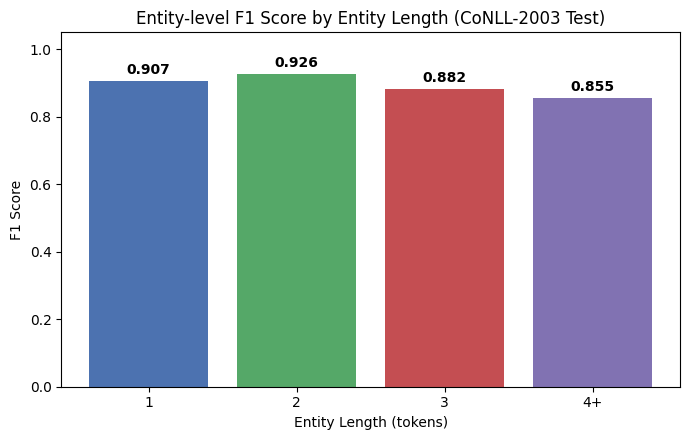

In [13]:
def extract_spans(tags):
    spans = []
    start, ent_type = None, None
    for i, tag in enumerate(tags):
        if tag.startswith("B-"):
            if ent_type is not None:
                spans.append((ent_type, start, i - 1))
            ent_type, start = tag[2:], i
        elif tag.startswith("I-"):
            if ent_type == tag[2:]:
                continue
            else:
                if ent_type is not None:
                    spans.append((ent_type, start, i - 1))
                ent_type, start = tag[2:], i
        else:
            if ent_type is not None:
                spans.append((ent_type, start, i - 1))
                ent_type, start = None, None
    if ent_type is not None:
        spans.append((ent_type, start, len(tags) - 1))
    return spans

def length_bucket(span):
    length = span[2] - span[1] + 1
    return "4+" if length >= 4 else str(length)

buckets = ["1", "2", "3", "4+"]
stats = {b: {"tp": 0, "fp": 0, "fn": 0} for b in buckets}

for g_seq, p_seq in zip(bert_true_seqs, bert_pred_seqs):
    g_spans = set(extract_spans(g_seq))
    p_spans = set(extract_spans(p_seq))

    for s in (g_spans & p_spans):
        stats[length_bucket(s)]["tp"] += 1
    for s in (p_spans - g_spans):
        stats[length_bucket(s)]["fp"] += 1
    for s in (g_spans - p_spans):
        stats[length_bucket(s)]["fn"] += 1

len_rows = []
for b in buckets:
    tp, fp, fn = stats[b]["tp"], stats[b]["fp"], stats[b]["fn"]
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    len_rows.append({"Entity_Length": b, "Gold_Count": tp + fn, "Precision": round(p, 4), "Recall": round(r, 4), "F1": round(f1, 4)})

len_df = pd.DataFrame(len_rows)
print("EXPERIMENT 5: PHÂN TÍCH THEO ĐỘ DÀI ENTITY")
display(len_df)

plt.figure(figsize=(7, 4.5))
bars = plt.bar(len_df["Entity_Length"], len_df["F1"], color=["#4c72b0", "#55a868", "#c44e52", "#8172b2"])
plt.ylim(0, 1.05)
plt.title("Entity-level F1 Score by Entity Length (CoNLL-2003 Test)")
plt.xlabel("Entity Length (tokens)")
plt.ylabel("F1 Score")
for bar, val in zip(bars, len_df["F1"]):
    plt.text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.3f}", ha="center", fontweight="bold")
plt.tight_layout()
plt.savefig("entity_length_analysis.png", dpi=150)
plt.show()

# 8, Error Analysis & Context Analysis

## Experiment 6: Trích xuất tự động tối thiểu 5 FP, 5 FN, 5 Boundary Errors

In [14]:
fp_list, fn_list, boundary_list, wrong_type_list = [], [], [], []

for idx, (ex, g_seq, p_seq) in enumerate(zip(raw_datasets["test"], bert_true_seqs, bert_pred_seqs)):
    words = ex["tokens"][:len(g_seq)]
    sent_text = " ".join(words)
    g_spans = set(extract_spans(g_seq))
    p_spans = set(extract_spans(p_seq))

    unmatched_g = list(g_spans - p_spans)
    unmatched_p = list(p_spans - g_spans)

    matched_g_idx = set()
    matched_p_idx = set()

    # 1. Wrong Entity Type & Boundary Error
    for pi, (pt, ps, pe) in enumerate(unmatched_p):
        for gi, (gt, gs, ge) in enumerate(unmatched_g):
            if max(ps, gs) <= min(pe, ge): # Có chồng lấn vị trí
                matched_p_idx.add(pi)
                matched_g_idx.add(gi)
                g_str = f"{' '.join(words[gs:ge+1])} ({gt})"
                p_str = f"{' '.join(words[ps:pe+1])} ({pt})"
                if ps == gs and pe == ge and pt != gt:
                    wrong_type_list.append((sent_text, g_str, p_str, "wrong entity type"))
                else:
                    boundary_list.append((sent_text, g_str, p_str, "wrong boundary"))
                break

    # 2. False Positives
    for pi, (pt, ps, pe) in enumerate(unmatched_p):
        if pi not in matched_p_idx:
            p_str = f"{' '.join(words[ps:pe+1])} ({pt})"
            fp_list.append((sent_text, "NONE", p_str, "spurious entity (FP)"))

    # 3. False Negatives
    for gi, (gt, gs, ge) in enumerate(unmatched_g):
        if gi not in matched_g_idx:
            g_str = f"{' '.join(words[gs:ge+1])} ({gt})"
            fn_list.append((sent_text, g_str, "NONE", "missing entity (FN)"))

print(f"Tổng số lỗi tìm thấy trên tập Test:")
print(f"  False Positives (Spurious) : {len(fp_list)}")
print(f"  False Negatives (Missing)  : {len(fn_list)}")
print(f"  Boundary Errors            : {len(boundary_list)}")
print(f"  Wrong Entity Type          : {len(wrong_type_list)}")

# (5 FP, 5 FN, 5 Boundary + 3 Wrong Type)
selected_errors = fp_list[:5] + fn_list[:5] + boundary_list[:5] + wrong_type_list[:3]
err_df = pd.DataFrame(selected_errors, columns=["Text", "Gold", "Prediction", "Error_type"])
pd.set_option("display.max_colwidth", 120)
display(err_df)

Tổng số lỗi tìm thấy trên tập Test:
  False Positives (Spurious) : 157
  False Negatives (Missing)  : 89
  Boundary Errors            : 167
  Wrong Entity Type          : 232


,Text,Gold,Prediction,Error_type
0,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRISE DEFEAT .",NONE,LUCKY (PER),spurious entity (FP)
1,Japan began the defence of their Asian Cup title with a lucky 2-1 win against Syria in a Group C championship match ...,NONE,C (MISC),spurious entity (FP)
2,"League title-holders Steaua Bucharest , who finished bottom of their Champions ' League group in the European Cup , ...",NONE,League (MISC),spurious entity (FP)
3,CRICKET - LARA SUFFERS MORE AUSTRALIAN TOUR MISERY .,NONE,MISERY (LOC),spurious entity (FP)
4,CRICKET - LARA SUFFERS MORE AUSTRALIAN TOUR MISERY .,NONE,AUSTRALIAN (MISC),spurious entity (FP)
5,RUGBY UNION - CUTTITTA BACK FOR ITALY AFTER A YEAR .,ITALY (LOC),NONE,missing entity (FN)
6,RUGBY UNION - LITTLE TO MISS CAMPESE FAREWELL .,CAMPESE (PER),NONE,missing entity (FN)
7,CRICKET - AUSTRALIA V WEST INDIES WORLD SERIES SCOREBOARD .,WORLD SERIES (MISC),NONE,missing entity (FN)
8,CRICKET - AUSTRALIA V WEST INDIES WORLD SERIES SCOREBOARD .,WEST INDIES (LOC),NONE,missing entity (FN)
9,CRICKET - AUSTRALIA BEAT WEST INDIES BY FIVE WICKETS .,WEST INDIES (LOC),NONE,missing entity (FN)


## Context Analysis

In [15]:
from collections import defaultdict

word_to_contexts = defaultdict(lambda: defaultdict(list))

for ex, g_seq, p_seq in zip(raw_datasets["test"], bert_true_seqs, bert_pred_seqs):
    words = ex["tokens"][:len(g_seq)]
    sent = " ".join(words)
    for i, (w, g, p) in enumerate(zip(words, g_seq, p_seq)):
        if g != "O":
            ent_type = g[2:]
            word_to_contexts[w][ent_type].append((sent, g, p))

ambiguous_words = [w for w, types in word_to_contexts.items() if len(types) >= 2]
print(f"{len(ambiguous_words)} từ có cùng mặt chữ nhưng khác loại Entity trong tập Test")
print("Một vài ví dụ tiêu biểu:\n")

for w in ambiguous_words[:5]:
    print(f"Surface form: '{w}'")
    for etype, items in word_to_contexts[w].items():
        sent, g_tag, p_tag = items[0]
        status = "ĐÚNG" if g_tag == p_tag else "SAI"
        print(f"  [{etype}] Gold={g_tag:6s} | Pred={p_tag:6s} ({status}) | Câu: {sent[:110]}")
    print()

213 từ có cùng mặt chữ nhưng khác loại Entity trong tập Test
Một vài ví dụ tiêu biểu:

Surface form: 'United'
  [LOC] Gold=B-LOC  | Pred=B-LOC  (ĐÚNG) | Câu: AL-AIN , United Arab Emirates 1996-12-06
  [ORG] Gold=I-ORG  | Pred=I-ORG  (ĐÚNG) | Câu: Two Manchester United soccer fans were wounded by unidentified gunmen on Friday and taken to hospital in the A

Surface form: 'Arab'
  [LOC] Gold=I-LOC  | Pred=I-LOC  (ĐÚNG) | Câu: AL-AIN , United Arab Emirates 1996-12-06
  [ORG] Gold=B-ORG  | Pred=B-ORG  (ĐÚNG) | Câu: Result of the second leg of the African Cup Winners ' Cup final at the National stadium on Friday : Arab Contr

Surface form: 'Japan'
  [LOC] Gold=B-LOC  | Pred=B-LOC  (ĐÚNG) | Câu: Japan began the defence of their Asian Cup title with a lucky 2-1 win against Syria in a Group C championship 
  [ORG] Gold=I-ORG  | Pred=I-ORG  (ĐÚNG) | Câu: In a rare expression of a view on currencies by the Bank of Japan ( BOJ ) governor , Yasuo Matsushita was quot

Surface form: 'Asian'
  [MISC]

# 9, Information Extraction Application

## Mini Information Extraction Pipeline (Option A: News)

In [16]:
import json

def extract_ie_from_text(text):
    enc = tokenizer(text, return_offsets_mapping=True, return_tensors="pt", truncation=True)
    offsets = enc.pop("offset_mapping")[0].tolist()
    word_ids = enc.word_ids(batch_index=0)
    enc = {k: v.to(device) for k, v in enc.items()}

    model.eval()
    with torch.no_grad():
        logits = model(**enc).logits[0]
    pred_ids = torch.argmax(logits, dim=-1).cpu().tolist()

    entities = []
    cur_type, cur_start, cur_end = None, None, None
    prev_wid = None

    for idx, (wid, (s_char, e_char), pid) in enumerate(zip(word_ids, offsets, pred_ids)):
        if wid is None:
            continue
        if wid == prev_wid:
            if cur_type is not None:
                cur_end = e_char
            continue
        prev_wid = wid
        tag = id2label[pid]

        if tag.startswith("B-"):
            if cur_type is not None:
                entities.append((cur_type, text[cur_start:cur_end]))
            cur_type, cur_start, cur_end = tag[2:], s_char, e_char
        elif tag.startswith("I-") and cur_type == tag[2:]:
            cur_end = e_char
        else:
            if cur_type is not None:
                entities.append((cur_type, text[cur_start:cur_end]))
                cur_type, cur_start, cur_end = None, None, None

    if cur_type is not None:
        entities.append((cur_type, text[cur_start:cur_end]))

    # Map sang format Option A: News (PERSON, ORG, LOCATION)
    result = {"PERSON": [], "ORG": [], "LOCATION": []}
    map_type = {"PER": "PERSON", "ORG": "ORG", "LOC": "LOCATION"}
    for etype, val in entities:
        if etype in map_type and val not in result[map_type[etype]]:
            result[map_type[etype]].append(val)
    return result

# Demo trên các câu tin tức
demo_sentences = [
    "Barack Obama visited Paris.",
    "Elon Musk founded SpaceX in California and later acquired Twitter.",
    "Apple and Microsoft announced a new AI partnership in New York."
]
for s in demo_sentences:
    print("Input :", s)
    print("Output:", json.dumps(extract_ie_from_text(s), ensure_ascii=False))
    print()

Input : Barack Obama visited Paris.
Output: {"PERSON": ["Barack Obama"], "ORG": [], "LOCATION": ["Paris"]}

Input : Elon Musk founded SpaceX in California and later acquired Twitter.
Output: {"PERSON": ["Elon Musk"], "ORG": ["SpaceX", "Twitter"], "LOCATION": ["California"]}

Input : Apple and Microsoft announced a new AI partnership in New York.
Output: {"PERSON": [], "ORG": ["Apple", "Microsoft"], "LOCATION": ["New York"]}



## Đánh giá IE bằng Entity-Level

In [17]:
eval_30_samples = []
for ex in raw_datasets["test"]:
    spans = [s for s in extract_spans([id2label[t] for t in ex["ner_tags"]]) if s[0] in {"PER", "ORG", "LOC"}]
    if len(spans) >= 2 and len(ex["tokens"]) >= 8:
        eval_30_samples.append((ex["tokens"], spans))
    if len(eval_30_samples) == 30:
        break

map_type = {"PER": "PERSON", "ORG": "ORG", "LOC": "LOCATION"}
ie_tp, ie_fp, ie_fn = 0, 0, 0

for tokens, gold_spans in eval_30_samples:
    raw_text = " ".join(tokens)
    gold_set = set((map_type[et], " ".join(tokens[s:e+1])) for et, s, e in gold_spans)

    pred_dict = extract_ie_from_text(raw_text)
    pred_set = set((k, v) for k, vals in pred_dict.items() for v in vals)

    ie_tp += len(gold_set & pred_set)
    ie_fp += len(pred_set - gold_set)
    ie_fn += len(gold_set - pred_set)

ie_p = ie_tp / (ie_tp + ie_fp) if (ie_tp + ie_fp) > 0 else 0
ie_r = ie_tp / (ie_tp + ie_fn) if (ie_tp + ie_fn) > 0 else 0
ie_f1 = 2 * ie_p * ie_r / (ie_p + ie_r) if (ie_p + ie_r) > 0 else 0

print("ÁNH GIÁ MINI INFORMATION EXTRACTION (30 CÂU TIN TỨC)")
print(f"TP = {ie_tp}, FP = {ie_fp}, FN = {ie_fn}")
print(f"Entity-level Precision : {ie_p:.4f}")
print(f"Entity-level Recall    : {ie_r:.4f}")
print(f"Entity-level F1        : {ie_f1:.4f}")

ÁNH GIÁ MINI INFORMATION EXTRACTION (30 CÂU TIN TỨC)
TP = 110, FP = 6, FN = 6
Entity-level Precision : 0.9483
Entity-level Recall    : 0.9483
Entity-level F1        : 0.9483


# 10, Reflection

Một trong những bước tiến quan trọng nhất của xử lý ngôn ngữ tự nhiên hiện đại là khả năng tái sử dụng cùng một mô hình Pretrained Transformer cho nhiều bài toán hoàn toàn khác nhau, điển hình là từ Sequence Classification (LAB 08) sang Token Classification (LAB 09), mà chỉ cần thay đổi phần prediction head ở tầng đầu ra. Lý do cốt lõi nằm ở bản chất kiến trúc của Transformer: mô hình đóng vai trò là một backbone chuyên tạo ra biểu diễn ngữ cảnh (contextual representation) giàu thông tin cho toàn bộ chuỗi đầu vào.

Cụ thể, khi một chuỗi gồm $T$ token đi qua nhiều lớp Self-Attention và Feed-Forward của Pretrained Transformer, mô hình không nén mất cấu trúc của từng từ mà trả về một ma trận trạng thái ẩn $H \in \mathbb{R}^{T \times d}$. Tại đây, mỗi vector hàng $h_i \in \mathbb{R}^d$ đại diện cho token thứ $i$, đồng thời đã tích hợp thông tin ngữ nghĩa, cú pháp và mối quan hệ phụ thuộc hai chiều với tất cả các token còn lại trong câu. Nhờ trải qua quá trình tiền huấn luyện (như Masked Language Modeling) trên lượng văn bản khổng lồ, các vector biểu diễn ngữ cảnh này vừa lưu giữ được ý nghĩa tổng quát của cả câu, vừa mã hóa chính xác vai trò cục bộ của từng từ trong ngữ cảnh hiện tại.

Chính sự giàu thông tin ở cả hai cấp độ này cho phép các tác vụ hạ nguồn (downstream tasks) khai thác ma trận $H$ theo hai nhánh khác nhau chỉ bằng cách gắn một đầu dự đoán (prediction head) phù hợp:

- Với Sequence Classification, ta chỉ cần trích xuất một vector đại diện duy nhất cho toàn bộ chuỗi — thường là vector tại token đặc biệt [CLS] (hoặc pooling các token) — rồi đưa qua một tầng tuyến tính (classification head) để ánh xạ thành phân phối xác suất cho một sequence label duy nhất (chẳng hạn cảm xúc tích cực/tiêu cực của cả đoạn đánh giá).

- Với Token Classification như bài toán NER, thay vì chỉ lấy [CLS], ta giữ lại toàn bộ biểu diễn của mọi token (every token) trong ma trận $H$. Một tầng tuyến tính dùng chung (token classifier head) $Z = HW + b$ được áp dụng đồng thời lên từng vector token để tạo ra vector logits tương ứng với các NER labels theo chuẩn BIO (B-, I-, O).

Cách thiết kế tách biệt giữa backbone học biểu diễn ngôn ngữ và prediction head định nghĩa không gian đầu ra mang lại sức mạnh tổng quát hóa cực lớn. Toàn bộ tri thức ngôn ngữ phức tạp đã nằm trong backbone và chỉ cần được tinh chỉnh nhẹ (fine-tune) theo hàm mất mát của tác vụ mới.